In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Understanding Product Categories
1.Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

In [5]:
category_frequency = df["category"].value_counts()

In [9]:
category_frequency.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2.Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

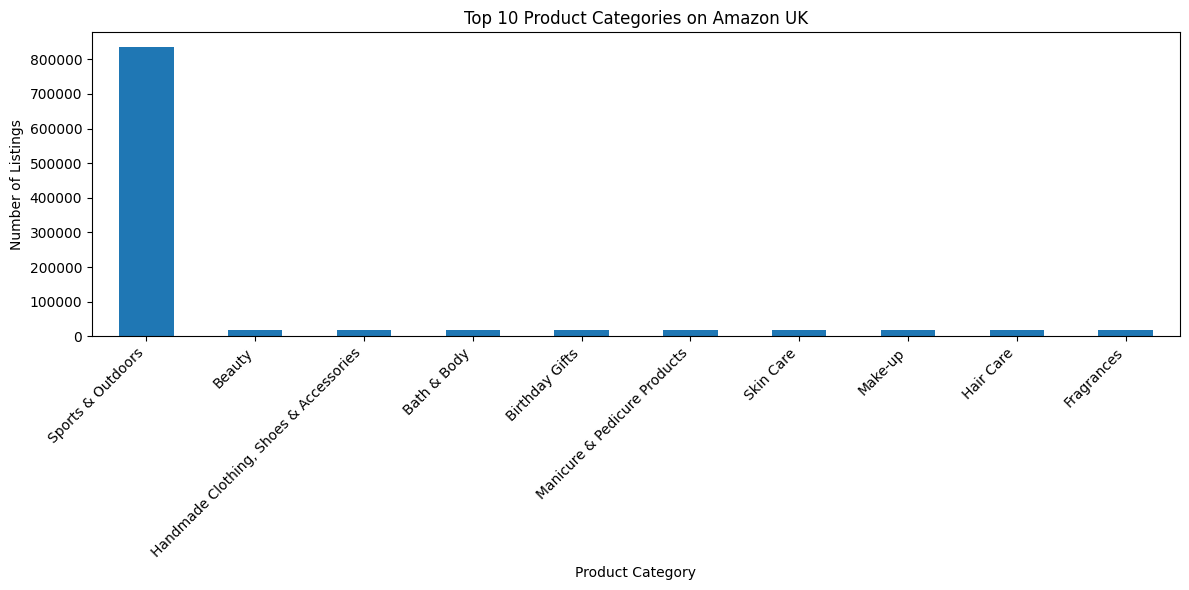

In [10]:
top_10_categories = category_frequency.head(10)

plt.figure(figsize=(12, 6))
top_10_categories.plot(kind="bar")

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Product Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1.Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [11]:
df["price"].head()

0    21.99
1    23.99
2    21.99
3    31.99
4    17.99
Name: price, dtype: float64

In [12]:
df["price"] = (
    df["price"]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["price"] = pd.to_numeric(df["price"], errors="coerce")

In [13]:
price_data = df["price"].dropna()

In [15]:
mean_price = price_data.mean()
median_price = price_data.median()
mode_price = price_data.mode()

print("Mean price:", round(mean_price, 2))

print("Median price:", round(median_price, 2))

print("Mode price:", mode_price)

Mean price: 89.24
Median price: 19.09
Mode price: 0    9.99
Name: price, dtype: float64


Comparing the mean and the mode, we can see whether the average price is influenced by expensive products.

The mean price is higher than the median and mode. This suggests that the price distribution is right-skewed, meaning that most products are listed at lower price points, while a smaller number of expensive products increase the average price.

2.Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

In [16]:
variance_price = price_data.var()
std_price = price_data.std()
price_range = price_data.max() - price_data.min()

q1 = price_data.quantile(0.25)
q3 = price_data.quantile(0.75)
iqr_price = q3 - q1

print("Variance:", round(variance_price, 2))
print("Standard Deviation:", round(std_price, 2))
print("Range:", round(price_range, 2))
print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr_price, 2))

Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.0
Q1: 9.99
Q3: 45.99
IQR: 36.0


The variance of product prices is 119,445.49, and the standard deviation is 345.61. This indicates that product prices are highly spread out around the average price.
The price range is 100,000.00, meaning there is a very large difference between the lowest and highest listed product prices. This suggests that the dataset contains some extremely expensive products compared with the majority of listings. 
Overall, the product prices show a significant spread. However, the relatively small IQR compared with the very large range suggests that most products are concentrated within a much narrower price band, while a small number of very high-priced products are likely acting as outliers. These extreme values increase the variance, standard deviation, and range.

3.Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

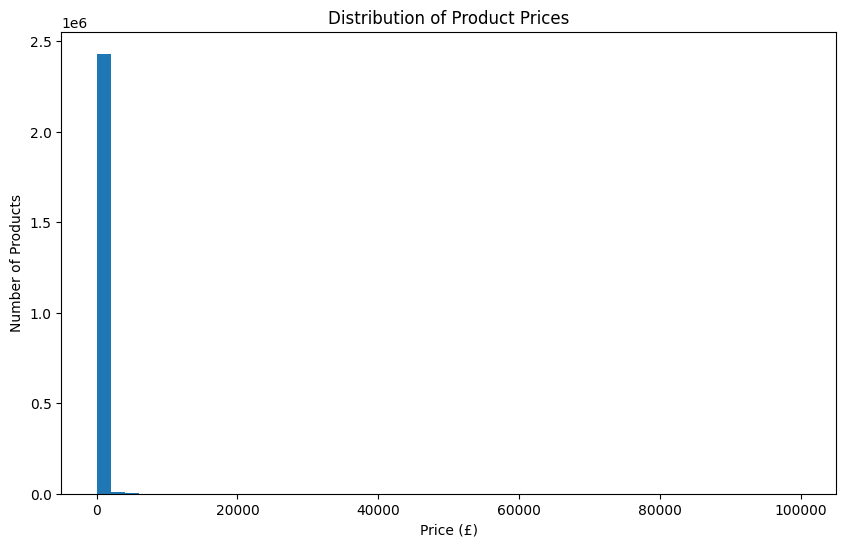

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(price_data, bins=50)

plt.title("Distribution of Product Prices")

plt.xlabel("Price (£)")

plt.ylabel("Number of Products")

plt.show()

this histogram may be hard to read because the product price range is extremely large. The range is £100,000, while the middle 50% of products are only between £9.99 and £45.99. This means that a few very expensive products stretch the x-axis, making most normal-priced products appear compressed on the left side of the chart.

A better solution is to focus on the typical price range by filtering out extreme values.

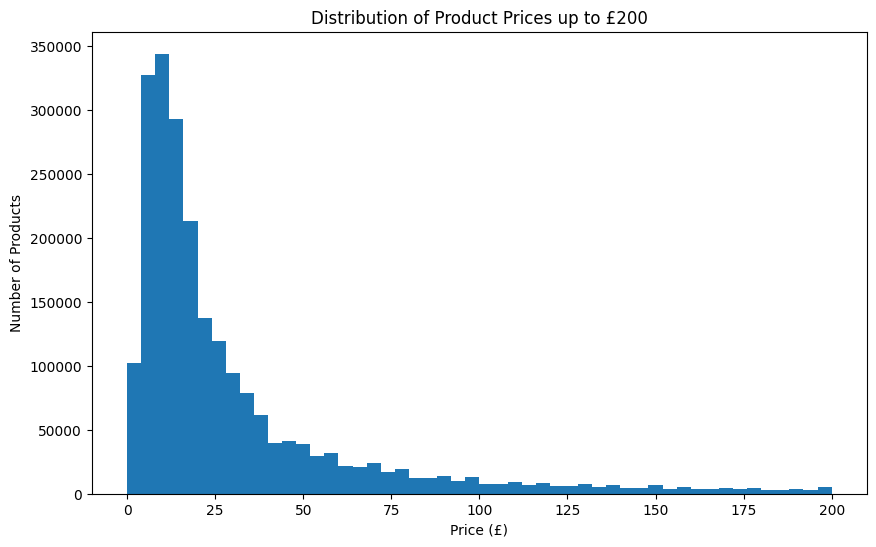

In [18]:
filtered_prices = price_data[price_data <= 200]

plt.figure(figsize=(10, 6))
plt.hist(filtered_prices, bins=50)

plt.title("Distribution of Product Prices up to £200")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1.Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?


In [20]:
df["stars"] = pd.to_numeric(df["stars"], errors="coerce")

rating_data = df["stars"].dropna()

rating_data.head()

0    4.7
1    4.7
2    4.7
3    4.7
4    4.6
Name: stars, dtype: float64

In [21]:
mean_rating = rating_data.mean()
median_rating = rating_data.median()
mode_rating = rating_data.mode()[0]

print("Mean rating:", round(mean_rating, 2))
print("Median rating:", round(median_rating, 2))
print("Mode rating:", mode_rating)

Mean rating: 2.15
Median rating: 0.0
Mode rating: 0.0


This suggests that the rating distribution is unusual. Since the median is 0.0, at least half of the products have a rating of 0.0 or close to 0.0. The mode is also 0.0, meaning that 0.0 is the most common rating in the dataset.

2.Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [22]:
variance_rating = rating_data.var()
std_rating = rating_data.std()

q1_rating = rating_data.quantile(0.25)
q3_rating = rating_data.quantile(0.75)
iqr_rating = q3_rating - q1_rating

print("Variance:", round(variance_rating, 2))
print("Standard Deviation:", round(std_rating, 2))
print("Q1:", round(q1_rating, 2))
print("Q3:", round(q3_rating, 2))
print("IQR:", round(iqr_rating, 2))

Variance: 4.82
Standard Deviation: 2.19
Q1: 0.0
Q3: 4.4
IQR: 4.4


The variance of product ratings is 4.82, and the standard deviation is 2.19. Since ratings are usually on a scale from 0 to 5, a standard deviation of 2.19 is quite high. This suggests that customer ratings are widely spread rather than being tightly grouped around the average.
Overall, the ratings show a wide variation in customer feedback. Some products have very low or missing-like ratings recorded as 0, while many others have relatively high ratings close to 4 or above. This indicates that ratings are not very consistent across products.

3.Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

In [23]:
skewness_rating = rating_data.skew()
kurtosis_rating = rating_data.kurtosis()

print("Skewness:", round(skewness_rating, 2))
print("Kurtosis:", round(kurtosis_rating, 2))

Skewness: 0.08
Kurtosis: -1.93


the Skewness is 0.08, that means distribution is almost balanced and does not strongly lean to the left or right.
The kurtosis is -1.93, which is strongly negative. This indicates a flat distribution compared with a normal distribution. In simple terms, the ratings are not tightly concentrated around one central value. Instead, they are spread across different rating levels, especially between 0.0 and higher ratings.

4.Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

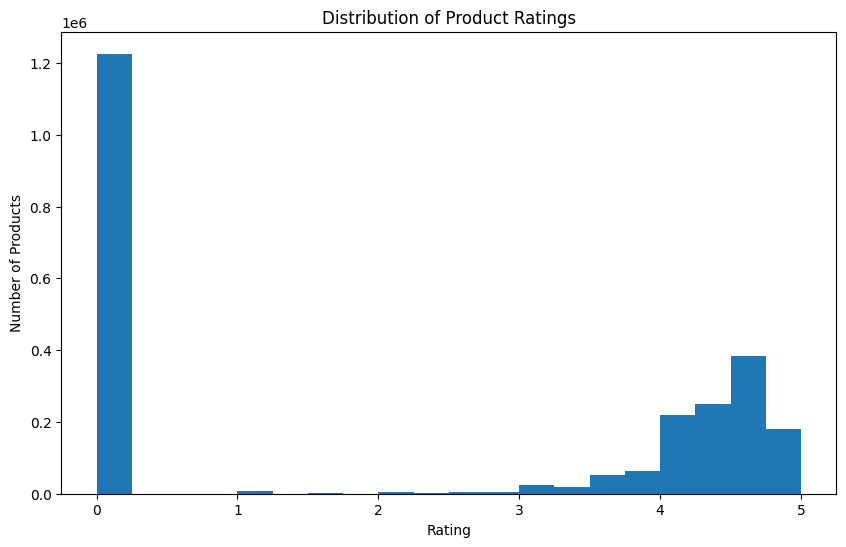

In [24]:
plt.figure(figsize=(10, 6))
plt.hist(rating_data, bins=20)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()